In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score

# Resistance in ohms

In [2]:
R_measured = np.array([98, 149, 198, 251, 298,
                       352, 398, 451, 498, 552], dtype=float)
R_nominal = np.array([100, 150, 200, 250, 300,
                      350, 400, 450, 500, 550], dtype=float)

# Capacitance in nF

In [3]:
C_measured = np.array([9.8, 19.6, 29.7, 39.5, 49.8,
                       59.4, 69.6, 79.5, 89.7, 99.4])
C_nominal = np.array([10, 20, 30, 40, 50,
                      60, 70, 80, 90, 100], dtype=float)

# Inductance in mH

In [4]:
L_measured = np.array([9.7, 19.8, 29.5, 40.4, 49.6,
                       60.3, 69.5, 80.2, 89.6, 100.5])
L_nominal = np.array([10, 20, 30, 40, 50,
                      60, 70, 80, 90, 100], dtype=float)

# 2. Regression and evaluation function

In [5]:
def estimate_parameter(measured, nominal, name, unit):

    X = measured.reshape(-1, 1)
    y = nominal

    model = LinearRegression()
    model.fit(X, y)

    predicted = model.predict(X)

    mae = mean_absolute_error(y, predicted)
    r2 = r2_score(y, predicted)

    percentage_error = (
        np.abs(predicted - y) / np.abs(y)
    ) * 100

    print(f"\n{name.upper()} ANALYSIS")
    print("-" * 35)
    print("Measured readings:", measured)
    print("Nominal values:", nominal)
    print("Predicted values:", np.round(predicted, 2))
    print("MAE:", round(mae, 3), unit)
    print("R-squared:", round(r2, 4))
    print("Mean percentage error:",
          round(np.mean(percentage_error), 2), "%")

    # Plot readings and regression predictions
    order = np.argsort(measured)

    plt.figure(figsize=(7, 4))
    plt.scatter(measured, nominal,
                label="Illustrative data")
    plt.plot(measured[order], predicted[order],
             label="Regression line")

    plt.xlabel(f"Measured {name} ({unit})")
    plt.ylabel(f"Nominal {name} ({unit})")
    plt.title(f"Regression Analysis of {name}")
    plt.legend()
    plt.grid(True)
    plt.show()

# 3. Estimate all three parameters


RESISTANCE ANALYSIS
-----------------------------------
Measured readings: [ 98. 149. 198. 251. 298. 352. 398. 451. 498. 552.]
Nominal values: [100. 150. 200. 250. 300. 350. 400. 450. 500. 550.]
Predicted values: [ 99.59 150.35 199.11 251.85 298.63 352.37 398.15 450.89 497.66 551.4 ]
MAE: 1.372 ohms
R-squared: 0.9999
Mean percentage error: 0.43 %


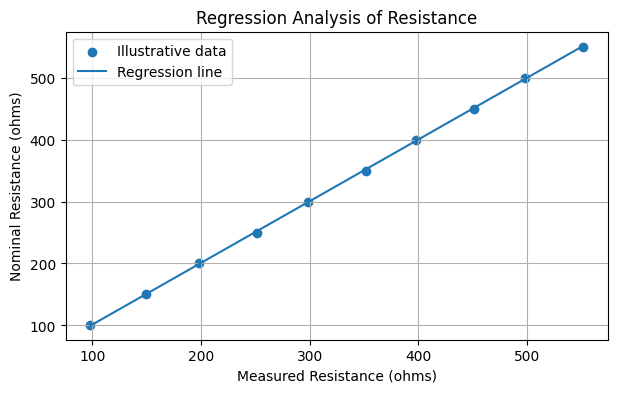


CAPACITANCE ANALYSIS
-----------------------------------
Measured readings: [ 9.8 19.6 29.7 39.5 49.8 59.4 69.6 79.5 89.7 99.4]
Nominal values: [ 10.  20.  30.  40.  50.  60.  70.  80.  90. 100.]
Predicted values: [10.09 19.92 30.04 39.86 50.19 59.81 70.04 79.96 90.18 99.91]
MAE: 0.108 nF
R-squared: 1.0
Mean percentage error: 0.29 %


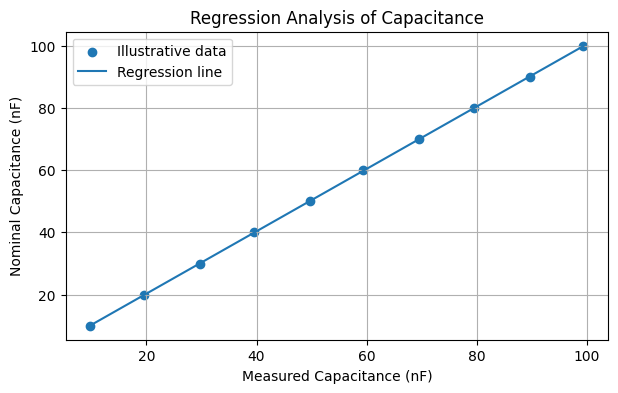


INDUCTANCE ANALYSIS
-----------------------------------
Measured readings: [  9.7  19.8  29.5  40.4  49.6  60.3  69.5  80.2  89.6 100.5]
Nominal values: [ 10.  20.  30.  40.  50.  60.  70.  80.  90. 100.]
Predicted values: [ 10.    20.05  29.71  40.56  49.71  60.37  69.52  80.17  89.53 100.38]
MAE: 0.306 mH
R-squared: 0.9999
Mean percentage error: 0.56 %


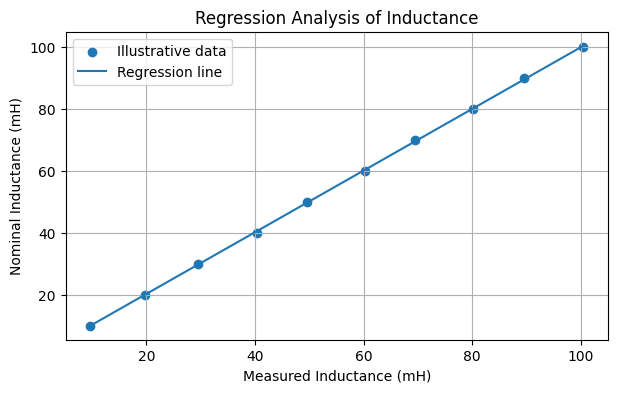

In [6]:
estimate_parameter(
    R_measured, R_nominal, "Resistance", "ohms"
)

estimate_parameter(
    C_measured, C_nominal, "Capacitance", "nF"
)

estimate_parameter(
    L_measured, L_nominal, "Inductance", "mH"
)